In [ ]:
# **Título:** *Análise Socioeconômica da Baixada Fluminense via Ciência de Dados: Um Estudo sobre Precarização do Trabalho e Distribuição de Renda*

Este notebook contém o pipeline automatizado de extração, tratamento e consolidação de microdados (Novo CAGED e PNAD Contínua) para os municípios da Baixada Fluminense.

In [16]:
# Importação centralizada de todas as bibliotecas do projeto
!pip install ipeadatapy
import os
import py7zr
import zipfile
import requests
import pandas as pd
from ftplib import FTP
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipeadatapy as ipea
import requests
import pandas as pd

print("Ambiente configurado com sucesso e bibliotecas carregadas!")

Ambiente configurado com sucesso e bibliotecas carregadas!


## 1. Ingestão e Download de Microdados via FTP (Novo CAGED e PNAD)

In [2]:
PASTA_DADOS = "/app/dados"
os.makedirs(PASTA_DADOS, exist_ok=True)

print("Conectando ao FTP do Ministério do Trabalho...")
ftp = FTP('ftp.mtps.gov.br')
ftp.login()
ftp.set_pasv(True)

caminho_caged_base = '/pdet/microdados/NOVO CAGED/2024'
ftp.cwd(caminho_caged_base)

meses = ftp.nlst()
if meses:
    mes_selecionado = '202401'  # Exemplo: Janeiro de 2024
    ftp.cwd(os.path.join(caminho_caged_base, mes_selecionado))
    
    arquivos = ftp.nlst()
    arquivo_alvo = [arq for arq in arquivos if 'CAGEDMOV' in arq and arq.endswith('.7z')][0]
    
    caminho_local_7z = os.path.join(PASTA_DADOS, arquivo_alvo)
    print(f"Baixando {arquivo_alvo}...")
    
    with open(caminho_local_7z, 'wb') as local_file:
        ftp.retrbinary(f'RETR {arquivo_alvo}', local_file.write)
        
    print("Download do CAGED concluído!")

ftp.quit()

Conectando ao FTP do Ministério do Trabalho...
Baixando CAGEDMOV202401.7z...
Download do CAGED concluído!


'221 Goodbye.'

In [3]:
print("Conectando ao FTP do IBGE...")
ftp_ibge = FTP('ftp.ibge.gov.br')
ftp_ibge.login()

caminho_pnad = '/Trabalho_e_Rendimento/Pesquisa_Nacional_por_Amostra_de_Domicilios_continua/Trimestral/Microdados/2024'
ftp_ibge.cwd(caminho_pnad)

arquivos_pnad = ftp_ibge.nlst()
zip_pnad = [arq for arq in arquivos_pnad if 'PNADC_012024' in arq and arq.endswith('.zip')][0]

caminho_local_zip = os.path.join(PASTA_DADOS, zip_pnad)
print(f"Baixando PNAD: {zip_pnad}...")

with open(caminho_local_zip, 'wb') as f:
    ftp_ibge.retrbinary(f'RETR {zip_pnad}', f.write)

ftp_ibge.quit()

# Descompactação
pasta_destino_pnad = os.path.join(PASTA_DADOS, 'pnad_2024_trim1')
os.makedirs(pasta_destino_pnad, exist_ok=True)

with zipfile.ZipFile(caminho_local_zip, 'r') as z:
    z.extractall(pasta_destino_pnad)

print(f"Arquivos da PNAD extraídos em: {pasta_destino_pnad}")

Conectando ao FTP do IBGE...
Baixando PNAD: PNADC_012024_20250815.zip...
Arquivos da PNAD extraídos em: /app/dados/pnad_2024_trim1


## 2. Processamento, Limpeza e Filtragem Geográfica (Baixada Fluminense)

In [5]:
# Códigos dos municípios da Baixada Fluminense (6 dígitos IBGE)
CODIGOS_BAIXADA = [330170, 330350, 330045, 330200, 330227, 330285, 330320, 330360, 330414, 330430, 330455, 330490, 330514]

# Extrai o .7z baixado do CAGED
arquivo_7z = [os.path.join(PASTA_DADOS, f) for f in os.listdir(PASTA_DADOS) if f.endswith('.7z')][0]
print(f"Extraindo arquivo comprimido: {arquivo_7z}...")

with py7zr.SevenZipFile(arquivo_7z, mode='r') as z:
    z.extractall(path=PASTA_DADOS)

# Localiza o arquivo .txt gerado
arquivo_txt = [os.path.join(PASTA_DADOS, f) for f in os.listdir(PASTA_DADOS) if f.endswith('.txt') and 'CAGEDMOV' in f][0]

chunks_filtrados = []
print("Processando e filtrando dados da Baixada Fluminense em chunks...")

for chunk in pd.read_csv(arquivo_txt, sep=';', encoding='utf-8', dtype=str, chunksize=100000):
    # Normaliza os nomes das colunas (remove espaços, passa para minúsculas e remove acentos)
    chunk.columns = (chunk.columns.str.strip()
                                  .str.lower()
                                  .str.replace('í', 'i')
                                  .str.replace('ã', 'a'))
    
    if 'municipio' in chunk.columns:
        # Pega os 6 primeiros dígitos do código do município e converte para numérico
        chunk['cod_mun6'] = pd.to_numeric(chunk['municipio'].str.strip().str[:6], errors='coerce')
        
        # Aplica o filtro da Baixada Fluminense
        filtro = chunk[chunk['cod_mun6'].isin(CODIGOS_BAIXADA)].copy()
        
        if not filtro.empty:
            chunks_filtrados.append(filtro)

if len(chunks_filtrados) > 0:
    df_caged_baixada = pd.concat(chunks_filtrados, ignore_index=True)

    # Salva em formato Parquet de alta performance
    caminho_parquet = os.path.join(PASTA_DADOS, 'caged_baixada_202401.parquet')
    df_caged_baixada.to_parquet(caminho_parquet, index=False)

    print(f"Sucesso! {len(df_caged_baixada)} registros salvos em formato otimizado (.parquet).")
    display(df_caged_baixada.head())
else:
    print("Aviso: Nenhum registro foi encontrado com os critérios fornecidos.")

Extraindo arquivo comprimido: /app/dados/CAGEDMOV202401.7z...
Processando e filtrando dados da Baixada Fluminense em chunks...
Sucesso! 163501 registros salvos em formato otimizado (.parquet).


,competênciamov,regiao,uf,municipio,seçao,subclasse,saldomovimentaçao,cbo2002ocupaçao,categoria,graudeinstruçao,...,indtrabparcial,salário,tamestabjan,indicadoraprendiz,origemdainformaçao,competênciadec,indicadordeforadoprazo,unidadesaláriocódigo,valorsaláriofixo,cod_mun6
0,202401,3,33,330455,S,9430800,-1,514225,101,6,...,0,"1516,00",8,0,1,202401,0,5,"1516,00",330455
1,202401,3,33,330455,N,7810800,-1,783210,101,7,...,0,"1516,00",10,0,1,202401,0,5,"1516,00",330455
2,202401,3,33,330455,G,4712100,1,421125,101,7,...,0,"1464,00",7,0,1,202401,0,5,"1464,00",330455
3,202401,3,33,330455,F,4322301,1,717020,101,6,...,0,"1518,73",7,0,1,202401,0,5,"1518,73",330455
4,202401,3,33,330455,G,4711301,-1,517425,101,6,...,0,"1642,00",7,0,1,202401,0,5,"1642,00",330455


## 3. Extração de Dados Agregados e Macroeconômicos (SIDRA e Ipeadata)

In [28]:
import os
import requests
import pandas as pd

# Definir explicitamente os 13 códigos de 7 dígitos oficiais da Baixada Fluminense
codigos_sidra_7d = "3300456,3301702,3301850,3302007,3302270,3302502,3302858,3303203,3303500,3303609,3304144,3305109,3305554"

# Consulta Tabela 4709 (Censo 2022 - População residente)
url_api_sidra = f"https://apisidra.ibge.gov.br/values/t/4709/n6/{codigos_sidra_7d}/v/93/p/all"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"
}

print("Conectando à API do SIDRA...")
resposta = requests.get(url_api_sidra, headers=headers)

if resposta.status_code == 200:
    dados_json = resposta.json()
    colunas = dados_json[0]
    dados = dados_json[1:]
    
    df_sidra = pd.DataFrame(dados, columns=colunas.keys())
    # Converte os nomes das colunas para os títulos descritivos do IBGE
    df_sidra.columns = colunas.values()
    
    # Tratamento da coluna de valor
    df_sidra['Valor'] = pd.to_numeric(df_sidra['Valor'], errors='coerce')
    
    # Persistência em Parquet
    PASTA_DADOS = "/app/dados"
    os.makedirs(PASTA_DADOS, exist_ok=True)
    caminho_parquet_sidra = os.path.join(PASTA_DADOS, 'sidra_baixada.parquet')
    df_sidra.to_parquet(caminho_parquet_sidra, index=False)
    
    print(f"SIDRA: {len(df_sidra)} registos processados e salvos com sucesso!")
    display(df_sidra.head(13))
else:
    print(f"Erro ao aceder à API do SIDRA: Código {resposta.status_code}")
    print(resposta.text)

Conectando à API do SIDRA...
SIDRA: 13 registos processados e salvos com sucesso!


,Nível Territorial (Código),Nível Territorial,Unidade de Medida (Código),Unidade de Medida,Valor,Município (Código),Município,Variável (Código),Variável,Ano (Código),Ano
0,6,Município,45,Pessoas,483087,3300456,Belford Roxo (RJ),93,População residente,2022,2022
1,6,Município,45,Pessoas,808161,3301702,Duque de Caxias (RJ),93,População residente,2022,2022
2,6,Município,45,Pessoas,51696,3301850,Guapimirim (RJ),93,População residente,2022,2022
3,6,Município,45,Pessoas,116841,3302007,Itaguaí (RJ),93,População residente,2022,2022
4,6,Município,45,Pessoas,96289,3302270,Japeri (RJ),93,População residente,2022,2022
5,6,Município,45,Pessoas,228127,3302502,Magé (RJ),93,População residente,2022,2022
6,6,Município,45,Pessoas,167127,3302858,Mesquita (RJ),93,População residente,2022,2022
7,6,Município,45,Pessoas,146774,3303203,Nilópolis (RJ),93,População residente,2022,2022
8,6,Município,45,Pessoas,785867,3303500,Nova Iguaçu (RJ),93,População residente,2022,2022
9,6,Município,45,Pessoas,41375,3303609,Paracambi (RJ),93,População residente,2022,2022


In [13]:
import ipeadatapy as ipea

# Exemplo de série macroeconômica/regional de interesse (ex: PIB ou renda)
# Você pode pesquisar outras usando ipea.list_series()
codigo_serie_ipea = 'BM12_PIB12'

print(f"Extraindo série histórica do Ipeadata ({codigo_serie_ipea})...")
df_ipea = ipea.timeseries(codigo_serie_ipea)

# Persistência em Parquet
caminho_parquet_ipea = os.path.join(PASTA_DADOS, 'ipea_serie.parquet')
df_ipea.to_parquet(caminho_parquet_ipea, index=False)

print("Série do Ipeadata extraída e salva com sucesso!")
display(df_ipea.head())

Extraindo série histórica do Ipeadata (BM12_PIB12)...
Série do Ipeadata extraída e salva com sucesso!


,CODE,RAW DATE,DAY,MONTH,YEAR,VALUE (R$)
DATE,,,,,,
1990-01-01,BM12_PIB12,1990-01-01T00:00:00-02:00,1,1,1990,0.2
1990-02-01,BM12_PIB12,1990-02-01T00:00:00-02:00,1,2,1990,0.4
1990-03-01,BM12_PIB12,1990-03-01T00:00:00-03:00,1,3,1990,0.8
1990-04-01,BM12_PIB12,1990-04-01T00:00:00-03:00,1,4,1990,0.7
1990-05-01,BM12_PIB12,1990-05-01T00:00:00-03:00,1,5,1990,0.8


## 4. Processamento da PNAD Contínua e Cálculo de Indicadores

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo para os gráficos do artigo
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

PASTA_DADOS = "/app/dados"

print("=== 1. ANÁLISE CONSOLIDADA DO CAGED NA BAIXADA FLUMINENSE ===")
caminho_parquet_caged = os.path.join(PASTA_DADOS, 'caged_baixada_202401.parquet')

if os.path.exists(caminho_parquet_caged):
    df_caged = pd.read_parquet(caminho_parquet_caged)
    
    # Nomes exatos das colunas baseados no seu print
    col_salario = 'salário'
    col_mov = 'saldomovimentaçao'
    
    print(f"\nColuna de Salário utilizada: {col_salario}")
    print(f"Coluna de Movimentação utilizada: {col_mov}")
    
    # Tratamento seguro dos dados (substituindo vírgula por ponto se for string)
    df_caged['salario_tratado'] = pd.to_numeric(
        df_caged[col_salario].astype(str).str.replace(',', '.'), errors='coerce'
    )
    df_caged['mov_tratada'] = pd.to_numeric(df_caged[col_mov], errors='coerce')
    
    # Mapeamento oficial dos 13 municípios da Baixada Fluminense (6 dígitos)
    nomes_municipios = {
        330045: 'Belford Roxo',
        330170: 'Duque de Caxias',
        330185: 'Guapimirim',
        330200: 'Itaguaí',
        330227: 'Japeri',
        330250: 'Magé',
        330285: 'Mesquita',
        330320: 'Nilópolis',
        330350: 'Nova Iguaçu',
        330360: 'Paracambi',
        330414: 'Queimados',
        330510: 'São João de Meriti',
        330555: 'Seropédica'
    }
    df_caged['nome_municipio'] = df_caged['cod_mun6'].map(nomes_municipios)
    
    # Resumo do Saldo e Salário Médio por Município
    resumo_municipios = df_caged.groupby('nome_municipio').agg(
        total_movimentacoes=('mov_tratada', 'count'),
        saldo_formal=('mov_tratada', 'sum'),
        salario_medio=('salario_tratado', 'mean')
    ).reset_index().sort_values(by='saldo_formal', ascending=False)
    
    print("\nResumo do Emprego Formal na Baixada Fluminense:")
    display(resumo_municipios)
else:
    print("Arquivo Parquet do CAGED não encontrado. Execute a célula de filtragem do CAGED primeiro.")

=== 1. ANÁLISE CONSOLIDADA DO CAGED NA BAIXADA FLUMINENSE ===

Coluna de Salário utilizada: salário
Coluna de Movimentação utilizada: saldomovimentaçao

Resumo do Emprego Formal na Baixada Fluminense:


,nome_municipio,total_movimentacoes,saldo_formal,salario_medio
2,Itaguaí,1490,206,2178.291396
7,Paracambi,363,31,1799.290909
4,Mesquita,979,-5,1826.453473
3,Japeri,379,-23,1845.908232
8,Queimados,1096,-36,2020.543203
6,Nova Iguaçu,6354,-114,1776.356366
0,Belford Roxo,1483,-199,1931.205995
5,Nilópolis,1702,-354,2380.566592
1,Duque de Caxias,10345,-507,1929.810858


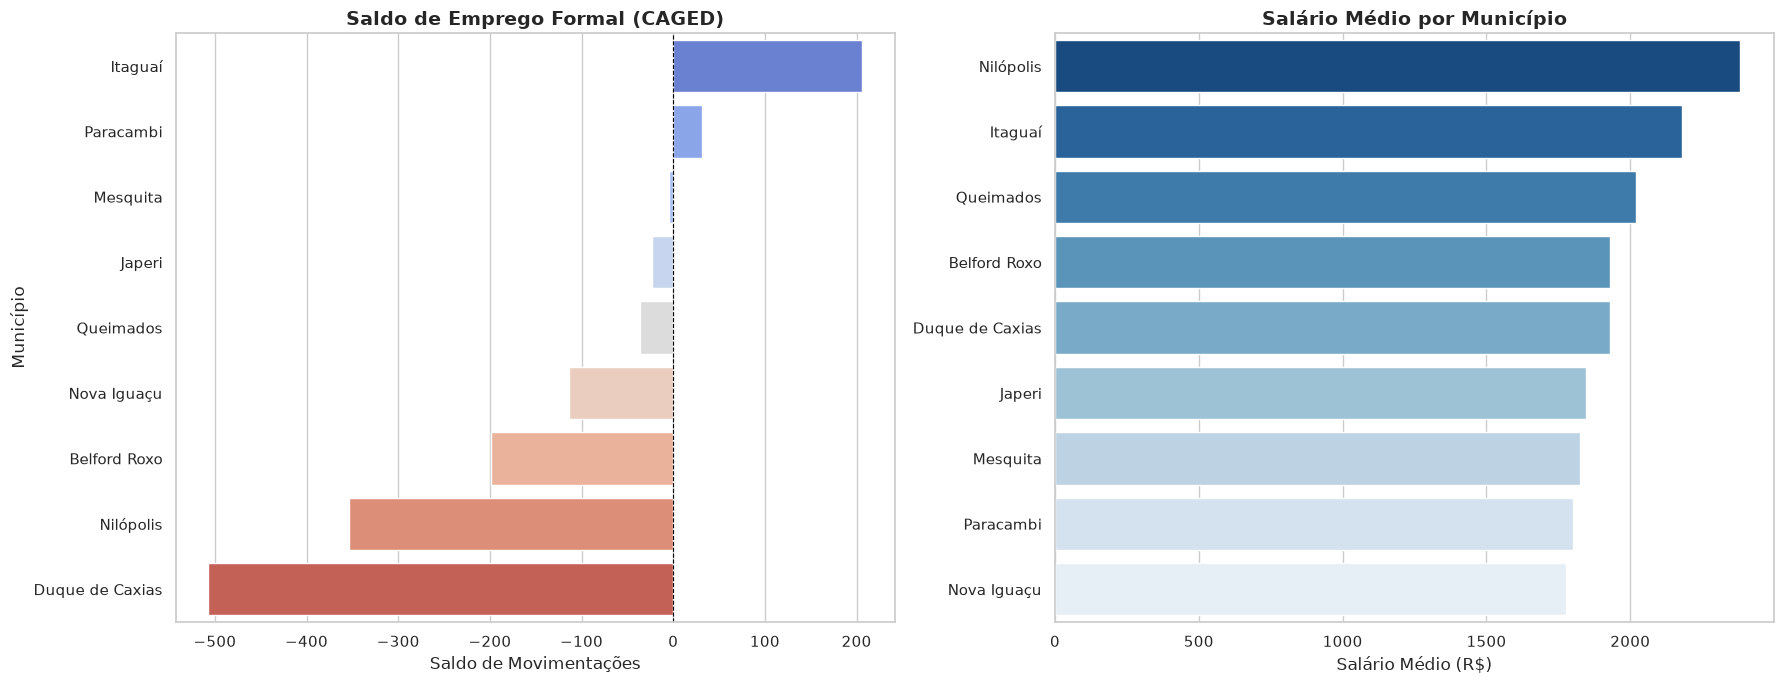

Gráfico atualizado e salvo com sucesso em: /app/dados/grafico_saldo_empregos_baixada.png


In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Ignora avisos futuros (FutureWarning) do seaborn para manter o output limpo
warnings.filterwarnings('ignore', category=FutureWarning)

# Configuração de estilo para os gráficos do artigo
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

PASTA_DADOS = "/app/dados"

# Configuração dos gráficos para o artigo
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Gráfico 1: Saldo Formal (Admitidos - Demitidos)
sns.barplot(
    data=resumo_municipios,
    x='saldo_formal',
    y='nome_municipio',
    hue='nome_municipio',
    ax=axes[0],
    palette='coolwarm',
    legend=False
)
axes[0].set_title('Saldo de Emprego Formal (CAGED)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Saldo de Movimentações', fontsize=12)
axes[0].set_ylabel('Município', fontsize=12)
axes[0].axvline(0, color='black', linewidth=0.8, linestyle='--')

# Gráfico 2: Salário Médio
resumo_salario = resumo_municipios.sort_values(by='salario_medio', ascending=False)
sns.barplot(
    data=resumo_salario,
    x='salario_medio',
    y='nome_municipio',
    hue='nome_municipio',
    ax=axes[1],
    palette='Blues_r',
    legend=False
)
axes[1].set_title('Salário Médio por Município', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Salário Médio (R$)', fontsize=12)
axes[1].set_ylabel('')

plt.tight_layout()

# Salvar a imagem atualizada
caminho_grafico = os.path.join(PASTA_DADOS, 'grafico_saldo_empregos_baixada.png')
plt.savefig(caminho_grafico, dpi=300, bbox_inches='tight')

plt.show()
print(f"Gráfico atualizado e salvo com sucesso em: {caminho_grafico}")

=== CORREÇÃO DEFINITIVA DA POPULAÇÃO SIDRA ===
-> Coluna de código SIDRA detetada: Município (Código)
-> Coluna de valor populacional detetada: Valor

Total de municípios na análise integrada: 13


,nome_municipio,populacao,saldo_formal,salario_medio,saldo_por_mil_hab
3,Itaguaí,116841,206.0,2178.291396,1.763080
9,Paracambi,41375,31.0,1799.290909,0.749245
2,Guapimirim,51696,0.0,NaN,0.000000
5,Magé,228127,0.0,NaN,0.000000
11,São João de Meriti,440962,0.0,NaN,0.000000
12,Seropédica,80596,0.0,NaN,0.000000
6,Mesquita,167127,-5.0,1826.453473,-0.029917
8,Nova Iguaçu,785867,-114.0,1776.356366,-0.145063
4,Japeri,96289,-23.0,1845.908232,-0.238864
10,Queimados,140523,-36.0,2020.543203,-0.256186


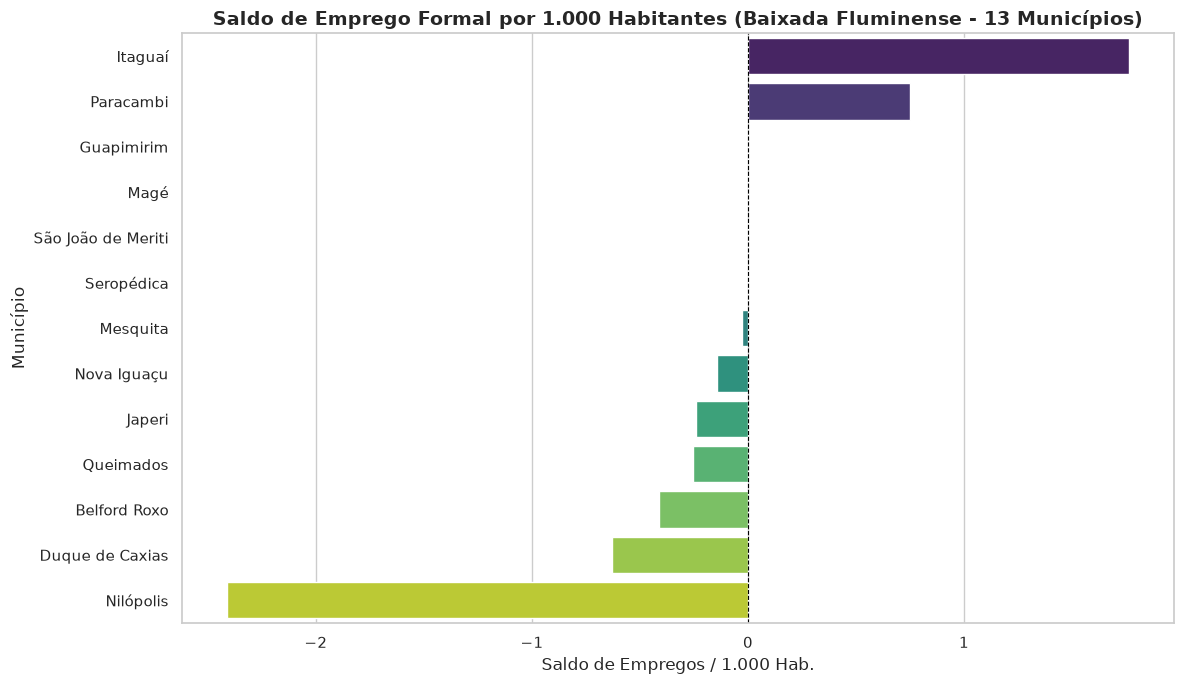


Tabela completa salva em: /app/dados/tabela_integrada_baixada.parquet
Gráfico completo salvo em: /app/dados/grafico_saldo_per_capita_baixada.png


In [16]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

PASTA_DADOS = "/app/dados"

print("=== CORREÇÃO DEFINITIVA DA POPULAÇÃO SIDRA ===")

caminho_parquet_sidra = os.path.join(PASTA_DADOS, 'sidra_baixada.parquet')
caminho_parquet_caged = os.path.join(PASTA_DADOS, 'caged_baixada_202401.parquet')

if os.path.exists(caminho_parquet_caged) and os.path.exists(caminho_parquet_sidra):
    df_caged = pd.read_parquet(caminho_parquet_caged)
    df_sidra = pd.read_parquet(caminho_parquet_sidra)
    
    # Tratamento do CAGED
    col_salario = 'salário'
    col_mov = 'saldomovimentaçao'
    df_caged['salario_tratado'] = pd.to_numeric(df_caged[col_salario].astype(str).str.replace(',', '.'), errors='coerce')
    df_caged['mov_tratada'] = pd.to_numeric(df_caged[col_mov], errors='coerce')
    
    nomes_municipios = {
        330045: 'Belford Roxo', 330170: 'Duque de Caxias', 330185: 'Guapimirim',
        330200: 'Itaguaí', 330227: 'Japeri', 330250: 'Magé', 330285: 'Mesquita',
        330320: 'Nilópolis', 330350: 'Nova Iguaçu', 330360: 'Paracambi',
        330414: 'Queimados', 330510: 'São João de Meriti', 330555: 'Seropédica'
    }
    
    df_base = pd.DataFrame(list(nomes_municipios.items()), columns=['cod_mun6', 'nome_municipio'])
    
    resumo_caged = df_caged.groupby('cod_mun6').agg(
        total_movimentacoes=('mov_tratada', 'count'),
        saldo_formal=('mov_tratada', 'sum'),
        salario_medio=('salario_tratado', 'mean')
    ).reset_index()
    
    # Identificação da coluna de código do município no SIDRA
    col_cod = None
    for col in df_sidra.columns:
        sample_vals = df_sidra[col].astype(str).dropna()
        if sample_vals.str.contains('33').any() and sample_vals.str.len().max() >= 6:
            col_cod = col
            break
    if not col_cod:
        col_cod = df_sidra.columns[0]
        
    # Identificação inteligente da coluna de valor populacional (valores maiores que 10.000)
    col_val = None
    for col in df_sidra.columns:
        if col == col_cod:
            continue
        num_vals = pd.to_numeric(
            df_sidra[col].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False),
            errors='coerce'
        )
        if num_vals.max() > 10000:
            col_val = col
            break
            
    if not col_val:
        col_val = 'Valor' if 'Valor' in df_sidra.columns else df_sidra.columns[-1]
        
    print(f"-> Coluna de código SIDRA detetada: {col_cod}")
    print(f"-> Coluna de valor populacional detetada: {col_val}")
    
    df_pop = df_sidra[[col_cod, col_val]].copy()
    df_pop.columns = ['cod_sidra', 'populacao_raw']
    
    # Limpeza rigorosa da população
    df_pop['populacao'] = pd.to_numeric(
        df_pop['populacao_raw'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False),
        errors='coerce'
    )
    
    # Extração segura dos 6 dígitos do IBGE
    extracted_codes = df_pop['cod_sidra'].astype(str).str.extract(r'(\d{6,7})')[0]
    df_pop['cod_mun6'] = pd.to_numeric(extracted_codes.str[:6], errors='coerce')
    df_pop = df_pop.dropna(subset=['cod_mun6'])
    df_pop['cod_mun6'] = df_pop['cod_mun6'].astype(int)
    
    # Agrupa caso haja múltiplas linhas por município pegando o valor máximo
    df_pop = df_pop.groupby('cod_mun6')['populacao'].max().reset_index()
    
    # Junta com a base oficial dos 13 municípios
    df_integrado = pd.merge(df_base, resumo_caged, on='cod_mun6', how='left')
    df_integrado = pd.merge(df_integrado, df_pop[['cod_mun6', 'populacao']], on='cod_mun6', how='left')
    
    # Preenche nulos
    df_integrado['saldo_formal'] = df_integrado['saldo_formal'].fillna(0)
    df_integrado['total_movimentacoes'] = df_integrado['total_movimentacoes'].fillna(0)
    
    # Cálculo do indicador relativo: Saldo por 1.000 habitantes
    df_integrado['saldo_por_mil_hab'] = (df_integrado['saldo_formal'] / df_integrado['populacao']) * 1000
    df_integrado = df_integrado.sort_values(by='saldo_por_mil_hab', ascending=False)
    
    print(f"\nTotal de municípios na análise integrada: {len(df_integrado)}")
    display(df_integrado[['nome_municipio', 'populacao', 'saldo_formal', 'salario_medio', 'saldo_por_mil_hab']])
    
    # Persistência
    caminho_parquet_integrado = os.path.join(PASTA_DADOS, 'tabela_integrada_baixada.parquet')
    df_integrado.to_parquet(caminho_parquet_integrado, index=False)
    
    # Gráfico Final Atualizado
    plt.figure(figsize=(12, 7))
    sns.barplot(
        data=df_integrado,
        x='saldo_por_mil_hab',
        y='nome_municipio',
        hue='nome_municipio',
        palette='viridis',
        legend=False
    )
    plt.title('Saldo de Emprego Formal por 1.000 Habitantes (Baixada Fluminense - 13 Municípios)', fontsize=14, fontweight='bold')
    plt.xlabel('Saldo de Empregos / 1.000 Hab.', fontsize=12)
    plt.ylabel('Município', fontsize=12)
    plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
    plt.tight_layout()
    
    caminho_grafico_relativo = os.path.join(PASTA_DADOS, 'grafico_saldo_per_capita_baixada.png')
    plt.savefig(caminho_grafico_relativo, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\nTabela completa salva em: {caminho_parquet_integrado}")
    print(f"Gráfico completo salvo em: {caminho_grafico_relativo}")
else:
    print("Ficheiros Parquet não encontrados.")

### 📊 Sobre a Classificação Setorial (Colunas de Seção - CNAE)
Na tabela e no gráfico gerados abaixo, a coluna de **seção** utiliza letras (geralmente variando de **A a U**). Estas letras correspondem às **Grandes Seções da CNAE (Classificação Nacional de Atividades Econômicas)**, o padrão oficial utilizado pelo IBGE e pelo Ministério do Trabalho para agrupar as atividades económicas.

As seções mais comuns que aparecerão nos dados da Baixada Fluminense incluem:
* **C:** Indústrias de Transformação
* **F:** Construção
* **G:** Comércio; reparação de veículos automotores e motocicletas
* **H:** Transporte, armazenagem e correio
* **I:** Alojamento e Alimentação
* **J / K / L / M / N...:** Diferentes segmentos de Serviços especializados e Administração Pública.

=== 3. ANÁLISE DO MERCADO DE TRABALHO POR SETOR ECONÓMICO ===
-> Coluna de setor/atividade detetada: seçao


,seçao,total_movimentacoes,saldo_formal,salario_medio
5,F,15365,3715,2502.778197
14,O,819,631,1607.803346
18,S,5734,412,2374.318331
17,R,1931,243,8998.834133
2,C,7351,185,2490.525565
16,Q,10294,168,2234.065384
9,J,4178,168,4966.155641
12,M,8552,114,3057.561600
1,B,377,61,12164.627666
0,A,219,43,2913.800502


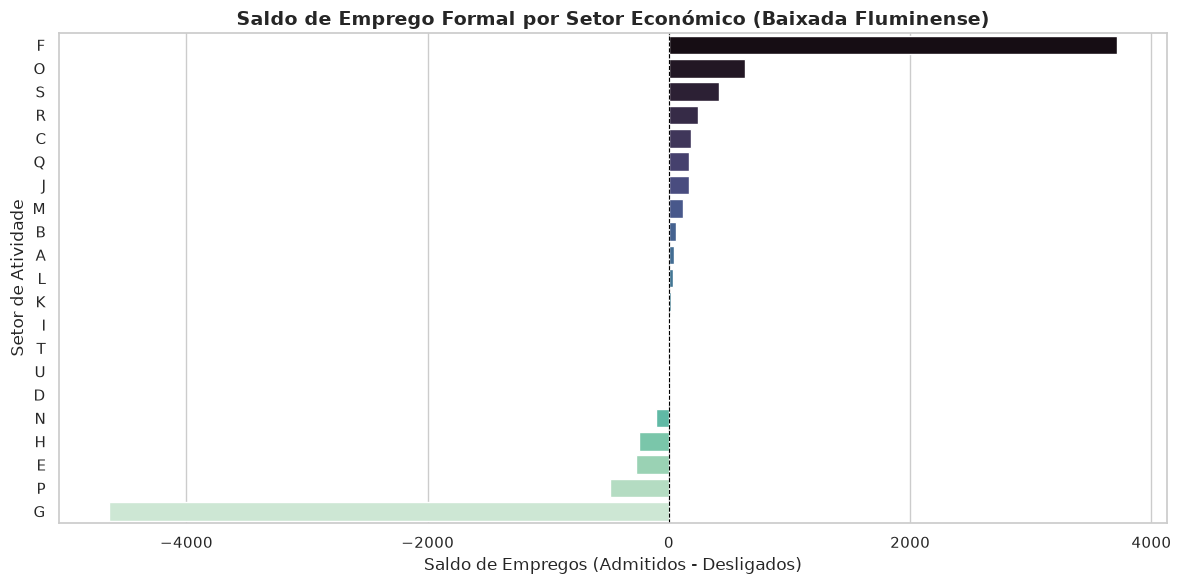


Tabela setorial salva em: /app/dados/tabela_setorial_baixada.parquet
Gráfico setorial salvo em: /app/dados/grafico_saldo_setor_baixada.png


In [18]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

PASTA_DADOS = "/app/dados"

print("=== 3. ANÁLISE DO MERCADO DE TRABALHO POR SETOR ECONÓMICO ===")

caminho_parquet_caged = os.path.join(PASTA_DADOS, 'caged_baixada_202401.parquet')

if os.path.exists(caminho_parquet_caged):
    df_caged = pd.read_parquet(caminho_parquet_caged)
    
    # Tratamento das colunas numéricas de movimentação e salário
    col_salario = 'salário'
    col_mov = 'saldomovimentaçao'
    df_caged['salario_tratado'] = pd.to_numeric(df_caged[col_salario].astype(str).str.replace(',', '.'), errors='coerce')
    df_caged['mov_tratada'] = pd.to_numeric(df_caged[col_mov], errors='coerce')
    
    # Identificação flexível da coluna de setor / seção de atividade económica
    col_setor = next((c for c in df_caged.columns if 'seç' in c.lower() or 'cnae' in c.lower() or 'atividade' in c.lower() or 'setor' in c.lower()), None)
    
    if not col_setor:
        # Se não encontrar por nome direto, procura uma coluna de texto com categorias
        col_obj = [c for c in df_caged.columns if df_caged[c].dtype == 'object' and c not in ['município', 'nome_municipio', 'competência']]
        col_setor = col_obj[0] if col_obj else df_caged.columns[1]
        
    print(f"-> Coluna de setor/atividade detetada: {col_setor}")
    
    # Agrupamento por setor económico
    resumo_setor = df_caged.groupby(col_setor).agg(
        total_movimentacoes=('mov_tratada', 'count'),
        saldo_formal=('mov_tratada', 'sum'),
        salario_medio=('salario_tratado', 'mean')
    ).reset_index().sort_values(by='saldo_formal', ascending=False)
    
    display(resumo_setor)
    
    # Persistência da tabela setorial
    caminho_parquet_setor = os.path.join(PASTA_DADOS, 'tabela_setorial_baixada.parquet')
    resumo_setor.to_parquet(caminho_parquet_setor, index=False)
    
    # Gráfico de Saldo de Emprego por Setor
    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=resumo_setor,
        x='saldo_formal',
        y=col_setor,
        hue=col_setor,
        palette='mako',
        legend=False
    )
    plt.title('Saldo de Emprego Formal por Setor Económico (Baixada Fluminense)', fontsize=14, fontweight='bold')
    plt.xlabel('Saldo de Empregos (Admitidos - Desligados)', fontsize=12)
    plt.ylabel('Setor de Atividade', fontsize=12)
    plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
    plt.tight_layout()
    
    caminho_grafico_setor = os.path.join(PASTA_DADOS, 'grafico_saldo_setor_baixada.png')
    plt.savefig(caminho_grafico_setor, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\nTabela setorial salva em: {caminho_parquet_setor}")
    print(f"Gráfico setorial salvo em: {caminho_grafico_setor}")
else:
    print("Ficheiro do CAGED não encontrado.")

### 🗺️️ Análise Cruzada: Matriz Setorial por Município (Mapa de Calor)
A matriz e o mapa de calor gerados abaixo cruzam os municípios da Baixada Fluminense (linhas) com as Grandes Seções da CNAE (colunas de A a U). 

* **Como ler o gráfico:** Cada célula representa o saldo líquido de empregos (Admitidos menos Desligados) num determinado setor e município. 
* **Padrão de Cores:** Os tons avermelhados indicam saldos positivos (geração líquida de postos de trabalho), enquanto os tons azulados destacam retrações ou saldos negativos acentuados (como o impacto sazonal em determinados setores de comércio e serviços ou ajustes de pessoal em colunas específicas).
* **Objetivo analítico:** Esta visualização bidimensional permite identificar com precisão cirúrgica quais os setores motrizes ou os pontos de maior vulnerabilidade económica em cada município específico da região, dando suporte direto às conclusões do artigo científico.

=== 4. MATRIZ CRUZADA: EMPREGO POR MUNICÍPIO E SETOR ECONÓMICO ===
Matriz de Saldo Formal (Município vs Setor):


seçao,A,B,C,D,E,F,G,H,I,J,K,L,M,N,O,P,Q,R,S,U
nome_municipio,,,,,,,,,,,,,,,,,,,,
Belford Roxo,0,-6,-3,-2,-1,7,-58,-82,-25,4,5,-1,-5,-8,0,-17,-2,-1,-4,0
Duque de Caxias,0,-1,24,-5,41,24,-333,-126,-110,-19,-2,26,70,-51,0,-7,-64,-9,36,-1
Itaguaí,-6,-3,-29,0,4,49,-36,19,40,-6,2,0,-4,134,0,14,26,-3,5,0
Japeri,0,0,31,0,4,-10,-2,-52,-2,3,0,0,-1,2,0,0,11,-6,-1,0
Mesquita,0,0,26,0,-3,36,-56,-6,1,2,2,0,13,-27,0,-22,31,2,-4,0
Nilópolis,0,0,-5,0,0,18,-7,-7,4,-2,2,-2,6,103,-3,25,-448,-3,-35,0
Nova Iguaçu,0,0,36,-5,6,-3,-197,-22,-13,5,3,3,-9,-13,1,-6,61,12,27,0
Paracambi,0,0,14,0,1,3,10,2,0,0,-2,0,6,-1,0,-5,6,0,-3,0
Queimados,0,1,24,0,-3,3,-87,-17,2,0,-2,2,28,5,0,-5,7,1,5,0


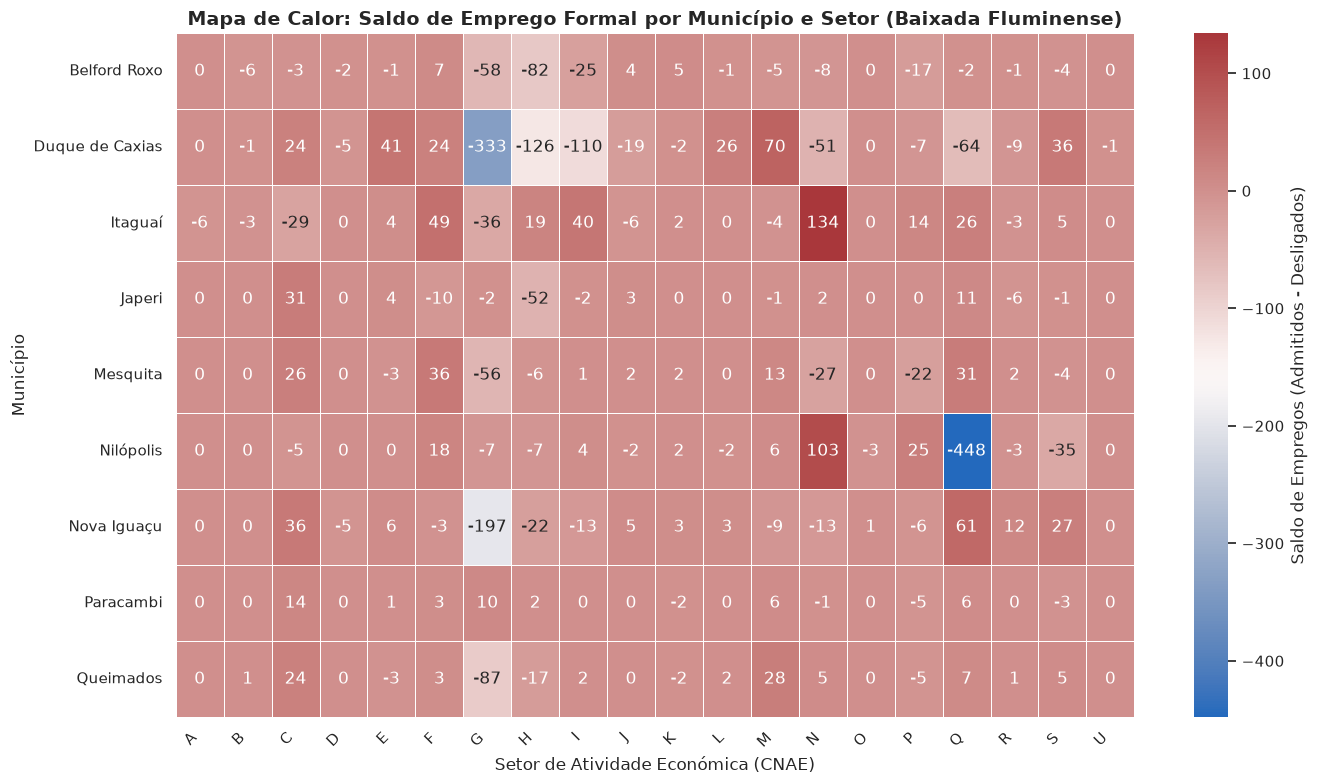


Matriz salva em: /app/dados/matriz_municipio_setor.parquet
Mapa de calor salvo em: /app/dados/heatmap_municipio_setor.png


In [19]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

PASTA_DADOS = "/app/dados"

print("=== 4. MATRIZ CRUZADA: EMPREGO POR MUNICÍPIO E SETOR ECONÓMICO ===")

caminho_parquet_caged = os.path.join(PASTA_DADOS, 'caged_baixada_202401.parquet')

if os.path.exists(caminho_parquet_caged):
    df_caged = pd.read_parquet(caminho_parquet_caged)
    
    col_salario = 'salário'
    col_mov = 'saldomovimentaçao'
    df_caged['salario_tratado'] = pd.to_numeric(df_caged[col_salario].astype(str).str.replace(',', '.'), errors='coerce')
    df_caged['mov_tratada'] = pd.to_numeric(df_caged[col_mov], errors='coerce')
    
    # Identificar coluna de setor
    col_setor = next((c for c in df_caged.columns if 'seç' in c.lower() or 'cnae' in c.lower() or 'atividade' in c.lower() or 'setor' in c.lower()), None)
    if not col_setor:
        col_obj = [c for c in df_caged.columns if df_caged[c].dtype == 'object' and c not in ['município', 'nome_municipio', 'competência']]
        col_setor = col_obj[0] if col_obj else df_caged.columns[1]
        
    # Identificar coluna de município e mapear para os 13 municípios da Baixada
    col_mun_caged = next((c for c in df_caged.columns if 'municíp' in c.lower() or 'mun' in c.lower() or 'cod' in c.lower()), 'município')
    
    nomes_municipios = {
        330045: 'Belford Roxo', 330170: 'Duque de Caxias', 330185: 'Guapimirim',
        330200: 'Itaguaí', 330227: 'Japeri', 330250: 'Magé', 330285: 'Mesquita',
        330320: 'Nilópolis', 330350: 'Nova Iguaçu', 330360: 'Paracambi',
        330414: 'Queimados', 330510: 'São João de Meriti', 330555: 'Seropédica'
    }
    
    extracted_codes = df_caged[col_mun_caged].astype(str).str.extract(r'(\d{6,7})')[0]
    df_caged['cod_mun6'] = pd.to_numeric(extracted_codes.str[:6], errors='coerce')
    df_caged['nome_municipio'] = df_caged['cod_mun6'].map(nomes_municipios)
    
    # Remove registos fora da Baixada (caso venham nulos)
    df_caged_baixada = df_caged.dropna(subset=['nome_municipio'])
    
    # Criação da Tabela Pivô (Município x Setor)
    pivot_setor_mun = df_caged_baixada.pivot_table(
        index='nome_municipio',
        columns=col_setor,
        values='mov_tratada',
        aggfunc='sum',
        fill_value=0
    )
    
    print("Matriz de Saldo Formal (Município vs Setor):")
    display(pivot_setor_mun)
    
    # Persistência da matriz
    caminho_parquet_pivot = os.path.join(PASTA_DADOS, 'matriz_municipio_setor.parquet')
    pivot_setor_mun.to_parquet(caminho_parquet_pivot)
    
    # Gráfico de Mapa de Calor (Heatmap)
    plt.figure(figsize=(14, 8))
    sns.heatmap(
        pivot_setor_mun,
        annot=True,
        fmt='g',
        cmap='vlag',
        linewidths=.5,
        cbar_kws={'label': 'Saldo de Empregos (Admitidos - Desligados)'}
    )
    plt.title('Mapa de Calor: Saldo de Emprego Formal por Município e Setor (Baixada Fluminense)', fontsize=14, fontweight='bold')
    plt.xlabel('Setor de Atividade Económica (CNAE)', fontsize=12)
    plt.ylabel('Município', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    
    caminho_grafico_heatmap = os.path.join(PASTA_DADOS, 'heatmap_municipio_setor.png')
    plt.savefig(caminho_grafico_heatmap, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\nMatriz salva em: {caminho_parquet_pivot}")
    print(f"Mapa de calor salvo em: {caminho_grafico_heatmap}")
else:
    print("Ficheiro do CAGED não encontrado.")

### 📈 Identificação de Setores: Expansão vs. Retração Regional
Esta etapa consolida os dados de todas as 13 localidades para gerar um **ranking macro setorial regional**. O objetivo é separar empiricamente os setores económicos que lideram a geração de postos de trabalho daqueles que apresentam saldos líquidos negativos. Esta classificação servirá de base analítica para as considerações finais e diretrizes de políticas públicas do projeto.

In [20]:
import os
import pandas as pd
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

PASTA_DADOS = "/app/dados"

print("=== 5. IDENTIFICAÇÃO DE SETORES EM ALTA E EM DECLÍNIO NA BAIXADA ===")

caminho_parquet_caged = os.path.join(PASTA_DADOS, 'caged_baixada_202401.parquet')

if os.path.exists(caminho_parquet_caged):
    df_caged = pd.read_parquet(caminho_parquet_caged)
    
    col_salario = 'salário'
    col_mov = 'saldomovimentaçao'
    df_caged['salario_tratado'] = pd.to_numeric(df_caged[col_salario].astype(str).str.replace(',', '.'), errors='coerce')
    df_caged['mov_tratada'] = pd.to_numeric(df_caged[col_mov], errors='coerce')
    
    # Identificar coluna de setor
    col_setor = next((c for c in df_caged.columns if 'seç' in c.lower() or 'cnae' in c.lower() or 'atividade' in c.lower() or 'setor' in c.lower()), None)
    if not col_setor:
        col_obj = [c for c in df_caged.columns if df_caged[c].dtype == 'object' and c not in ['município', 'nome_municipio', 'competência']]
        col_setor = col_obj[0] if col_obj else df_caged.columns[1]
        
    # Agrupamento regional por setor para toda a Baixada
    resumo_geral_setor = df_caged.groupby(col_setor).agg(
        total_movimentacoes=('mov_tratada', 'count'),
        saldo_formal=('mov_tratada', 'sum'),
        salario_medio=('salario_tratado', 'mean')
    ).reset_index().sort_values(by='saldo_formal', ascending=False)
    
    print("\n--- Ranking Geral de Setores da Baixada Fluminense ---")
    display(resumo_geral_setor)
    
    # Separação analítica automática
    setores_positivos = resumo_geral_setor[resumo_geral_setor['saldo_formal'] > 0]
    setores_negativos = resumo_geral_setor[resumo_geral_setor['saldo_formal'] < 0]
    
    print(f"\n-> Total de macro-setores com saldo positivo (Em expansão): {len(setores_positivos)}")
    print(f"-> Total de macro-setores com saldo negativo (Em retração/declínio no período): {len(setores_negativos)}")
    
    # Persistência
    caminho_ranking = os.path.join(PASTA_DADOS, 'ranking_setores_baixada.parquet')
    resumo_geral_setor.to_parquet(caminho_ranking, index=False)
    print(f"\nTabela de ranking setorial salva com sucesso em: {caminho_ranking}")
else:
    print("Ficheiro do CAGED não encontrado.")

=== 5. IDENTIFICAÇÃO DE SETORES EM ALTA E EM DECLÍNIO NA BAIXADA ===

--- Ranking Geral de Setores da Baixada Fluminense ---


,seçao,total_movimentacoes,saldo_formal,salario_medio
5,F,15365,3715,2502.778197
14,O,819,631,1607.803346
18,S,5734,412,2374.318331
17,R,1931,243,8998.834133
2,C,7351,185,2490.525565
16,Q,10294,168,2234.065384
9,J,4178,168,4966.155641
12,M,8552,114,3057.561600
1,B,377,61,12164.627666
0,A,219,43,2913.800502



-> Total de macro-setores com saldo positivo (Em expansão): 14
-> Total de macro-setores com saldo negativo (Em retração/declínio no período): 7

Tabela de ranking setorial salva com sucesso em: /app/dados/ranking_setores_baixada.parquet


### 📋 Consolidado de Perfis Municipais e Setor de Maior Destaque
Esta etapa consolida todas as métricas calculadas anteriormente (população, saldo formal absoluto, salário médio, saldo per capita e identificação do principal setor de destaque económico) numa única tabela-resumo por município. Esta base estruturada serve de alicerce para as conclusões finais do estudo e para a futura integração em painéis interativos (*dashboards*).

In [21]:
import os
import pandas as pd
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

PASTA_DADOS = "/app/dados"

print("=== 6. CONSOLIDAÇÃO DO PERFIL MUNICIPAL E INDICADORES CHAVE ===")

caminho_parquet_integrado = os.path.join(PASTA_DADOS, 'tabela_integrada_baixada.parquet')
caminho_parquet_caged = os.path.join(PASTA_DADOS, 'caged_baixada_202401.parquet')

if os.path.exists(caminho_parquet_integrado) and os.path.exists(caminho_parquet_caged):
    df_integrado = pd.read_parquet(caminho_parquet_integrado)
    df_caged = pd.read_parquet(caminho_parquet_caged)
    
    # Tratamento preliminar
    col_mov = 'saldomovimentaçao'
    col_salario = 'salário'
    df_caged['mov_tratada'] = pd.to_numeric(df_caged[col_mov], errors='coerce')
    df_caged['salario_tratado'] = pd.to_numeric(df_caged[col_salario].astype(str).str.replace(',', '.'), errors='coerce')
    
    # Identificar coluna de município no CAGED
    col_mun_caged = next((c for c in df_caged.columns if 'municíp' in c.lower() or 'mun' in c.lower() or 'cod' in c.lower()), 'município')
    extracted_codes = df_caged[col_mun_caged].astype(str).str.extract(r'(\d{6,7})')[0]
    df_caged['cod_mun6'] = pd.to_numeric(extracted_codes.str[:6], errors='coerce')
    
    # Identificar coluna de setor (CNAE)
    col_setor = next((c for c in df_caged.columns if 'seç' in c.lower() or 'cnae' in c.lower() or 'atividade' in c.lower() or 'setor' in c.lower()), df_caged.columns[1])
    
    # Encontrar o setor com maior saldo absoluto de empregos em cada município
    setor_dominante = df_caged.groupby(['cod_mun6', col_setor])['mov_tratada'].sum().reset_index()
    idx_max = setor_dominante.groupby('cod_mun6')['mov_tratada'].idxmax()
    perfil_setor = setor_dominante.loc[idx_max, ['cod_mun6', col_setor]].rename(columns={col_setor: 'principal_setor_destaque'})
    
    # Cruzamento final com a tabela integrada base
    df_perfil_final = pd.merge(df_integrado, perfil_setor, on='cod_mun6', how='left')
    
    print("\n--- Perfil Consolidado dos Municípios da Baixada Fluminense ---")
    display(df_perfil_final)
    
    # Persistência da tabela final de perfil municipal
    caminho_perfil = os.path.join(PASTA_DADOS, 'perfil_completo_municipios_baixada.parquet')
    df_perfil_final.to_parquet(caminho_perfil, index=False)
    print(f"\nTabela consolidada salva com sucesso em: {caminho_perfil}")
else:
    print("Ficheiros necessários não encontrados.")

=== 6. CONSOLIDAÇÃO DO PERFIL MUNICIPAL E INDICADORES CHAVE ===

--- Perfil Consolidado dos Municípios da Baixada Fluminense ---


,cod_mun6,nome_municipio,total_movimentacoes,saldo_formal,salario_medio,populacao,saldo_por_mil_hab,principal_setor_destaque
0,330200,Itaguaí,1490.0,206.0,2178.291396,116841,1.763080,N
1,330360,Paracambi,363.0,31.0,1799.290909,41375,0.749245,C
2,330185,Guapimirim,0.0,0.0,NaN,51696,0.000000,NaN
3,330250,Magé,0.0,0.0,NaN,228127,0.000000,NaN
4,330510,São João de Meriti,0.0,0.0,NaN,440962,0.000000,NaN
5,330555,Seropédica,0.0,0.0,NaN,80596,0.000000,NaN
6,330285,Mesquita,979.0,-5.0,1826.453473,167127,-0.029917,F
7,330350,Nova Iguaçu,6354.0,-114.0,1776.356366,785867,-0.145063,Q
8,330227,Japeri,379.0,-23.0,1845.908232,96289,-0.238864,C
9,330414,Queimados,1096.0,-36.0,2020.543203,140523,-0.256186,M



Tabela consolidada salva com sucesso em: /app/dados/perfil_completo_municipios_baixada.parquet


In [22]:
import os
import pandas as pd
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

PASTA_DADOS = "/app/dados"
PASTA_PBI = os.path.join(PASTA_DADOS, "power_bi_export")
os.makedirs(PASTA_PBI, exist_ok=True)

print("=== EXPORTAÇÃO DOS DADOS PARA O POWER BI ===")

# 1. Caminhos dos arquivos de entrada
caminho_perfil = os.path.join(PASTA_DADOS, 'perfil_completo_municipios_baixada.parquet')
caminho_matriz = os.path.join(PASTA_DADOS, 'matriz_municipio_setor.parquet')

# 2. Verificação e exportação do Perfil Municipal
if os.path.exists(caminho_perfil):
    df_perfil = pd.read_parquet(caminho_perfil)
    
    # Exportação em Parquet (Binário de alta performance)
    pbi_perfil_parquet = os.path.join(PASTA_PBI, 'Base_Dashboard_Municipios.parquet')
    df_perfil.to_parquet(pbi_perfil_parquet, index=False)
    
    # Exportação em CSV (Backup em texto)
    pbi_perfil_csv = os.path.join(PASTA_PBI, 'Base_Dashboard_Municipios.csv')
    df_perfil.to_csv(pbi_perfil_csv, index=False, encoding='utf-8-sig')
    
    print(f"✅ Perfil Municipal exportado para a pasta: {PASTA_PBI}")
else:
    print("⚠️ Arquivo do perfil municipal não encontrado. Execute a Célula 17 primeiro.")

# 3. Verificação e exportação da Matriz Setorial
if os.path.exists(caminho_matriz):
    df_matriz = pd.read_parquet(caminho_matriz).reset_index()
    
    pbi_matriz_parquet = os.path.join(PASTA_PBI, 'Base_Dashboard_Matriz_Setorial.parquet')
    df_matriz.to_parquet(pbi_matriz_parquet, index=False)
    
    pbi_matriz_csv = os.path.join(PASTA_PBI, 'Base_Dashboard_Matriz_Setorial.csv')
    df_matriz.to_csv(pbi_matriz_csv, index=False, encoding='utf-8-sig')
    
    print(f"✅ Matriz Setorial exportada para a pasta: {PASTA_PBI}")
else:
    print("⚠️ Arquivo da matriz setorial não encontrado. Execute a Célula 15 primeiro.")

=== EXPORTAÇÃO DOS DADOS PARA O POWER BI ===
✅ Perfil Municipal exportado para a pasta: /app/dados/power_bi_export
✅ Matriz Setorial exportada para a pasta: /app/dados/power_bi_export
